In [1]:
# ============================================================
# 1. Imports, reproducibility, and device
# ============================================================

import random
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

from configs.swin3d_small import TRAIN_CONFIG
from datasets.belize_laz_dataset import create_dataloaders
from losses.generalized_dice import GeneralizedDiceLoss
from losses.soft_avd import SoftAVDLoss
from models.swin3d_model import Model


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


/path/to/envs/maya_env/lib/python3.10/site-packages/MinkowskiEngine/__init__.py:36: UserWarning: The environment variable `OMP_NUM_THREADS` not set. MinkowskiEngine will automatically set `OMP_NUM_THREADS=16`. If you want to set `OMP_NUM_THREADS` manually, please export it on the command line before running a python script. e.g. `export OMP_NUM_THREADS=12; python your_program.py`. It is recommended to set it below 24.
  warnings.warn(


Device: cuda
GPU: Tesla V100-PCIE-32GB


In [2]:
# ============================================================
# 2. Training configuration
# ============================================================

print("Training configuration:")
for key, value in TRAIN_CONFIG.items():
    print(f"  {key}: {value}")

required_keys = [
    "num_classes",
    "voxel_max",
    "batch_size",
    "augmentation_ratio",
    "max_epochs",
    "warmup_epochs",
    "early_stopping_patience",
    "learning_rate",
    "weight_decay",
]

missing_keys = [
    key for key in required_keys
    if key not in TRAIN_CONFIG
]

if missing_keys:
    raise KeyError(
        f"Missing TRAIN_CONFIG keys: {missing_keys}"
    )

if TRAIN_CONFIG["warmup_epochs"] >= TRAIN_CONFIG["max_epochs"]:
    raise ValueError(
        "warmup_epochs must be smaller than max_epochs."
    )


Training configuration:
  dataset: BelizeSlopeValue_plz_str_grd_100m_06mslope
  num_classes: 3
  input_features: ['x', 'y', 'z', 'slope']
  voxel_size: 0.2
  voxel_max: 65000
  batch_size: 16
  augmentations: ['jitter', 'flip', 'rotation']
  augmentation_ratio: 6
  trainable_layers: all
  max_epochs: 100
  warmup_epochs: 10
  early_stopping_patience: 10
  loss_function: generalized_dice
  optimizer: AdamW
  learning_rate: 3e-05
  weight_decay: 0.001
  scheduler: cosine


In [4]:
# ============================================================
# 3. Data loaders
# ============================================================

train_loader, validation_loader, test_loader = create_dataloaders(
    split_dir="dataset_splits",
    batch_size=TRAIN_CONFIG["batch_size"],
    voxel_max=TRAIN_CONFIG["voxel_max"],
    num_workers=4,
    augmentation_ratio=TRAIN_CONFIG["augmentation_ratio"],
)

print("Training samples:", len(train_loader.dataset))
print("Validation samples:", len(validation_loader.dataset))
print("Test samples:", len(test_loader.dataset))

print()
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

print()
print(
    "Augmentation ratio:",
    TRAIN_CONFIG["augmentation_ratio"],
)


Training samples: 2226
Validation samples: 79
Test samples: 80

Training batches: 139
Validation batches: 5
Test batches: 5

Augmentation ratio: 6


In [5]:
# ============================================================
# 4. Batch and epoch helper functions
# ============================================================

def move_batch_to_device(batch, device):
    (
        coords,
        features,
        offset,
        labels,
        paths,
        metric_coords,
    ) = batch

    coords = coords.to(
        device,
        non_blocking=True,
    ).float()

    features = features.to(
        device,
        non_blocking=True,
    ).float()

    offset = offset.to(
        device,
        non_blocking=True,
    ).long()

    labels = labels.to(
        device,
        non_blocking=True,
    ).long()

    return coords, features, offset, labels


def calculate_batch_accuracy(logits, labels):
    predictions = logits.argmax(dim=1)

    correct = (
        predictions == labels
    ).sum().item()

    total = labels.numel()

    return correct, total


def train_one_epoch(
    model,
    loader,
    dice_criterion,
    avd_criterion,
    optimizer,
    device,
    dice_weight=0.75,
    avd_weight=0.25,
):
    model.train()

    total_loss = 0.0
    total_dice_loss = 0.0
    total_avd_loss = 0.0
    total_correct = 0
    total_points = 0

    for batch_index, batch in enumerate(loader):
        coords, features, offset, labels = (
            move_batch_to_device(
                batch,
                device,
            )
        )

        optimizer.zero_grad(set_to_none=True)

        logits = model(
            (coords, features, offset)
        )

        if isinstance(logits, tuple):
            logits = logits[0]

        if logits.shape[0] != labels.shape[0]:
            raise RuntimeError(
                "Logit and label point counts do not match: "
                f"logits={logits.shape}, labels={labels.shape}"
            )

        dice_loss = dice_criterion(
            logits,
            labels,
        )

        avd_loss = avd_criterion(
            logits=logits,
            targets=labels,
            coords=coords,
            offset=offset,
        )

        loss = (
            dice_weight * dice_loss
            +
            avd_weight * avd_loss
        )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss in batch {batch_index}: "
                f"{loss.item()}"
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
        )

        optimizer.step()

        correct, number_of_points = (
            calculate_batch_accuracy(
                logits,
                labels,
            )
        )

        total_loss += loss.item() * number_of_points
        total_dice_loss += dice_loss.item() * number_of_points
        total_avd_loss += avd_loss.item() * number_of_points
        total_correct += correct
        total_points += number_of_points

        if (
            batch_index == 0
            or (batch_index + 1) % 10 == 0
            or batch_index + 1 == len(loader)
        ):
            print(
                f"  Batch {batch_index + 1:04d}/"
                f"{len(loader):04d} | "
                f"Total: {loss.item():.6f} | "
                f"Dice: {dice_loss.item():.6f} | "
                f"Soft AVD: {avd_loss.item():.6f}"
            )

    denominator = max(total_points, 1)

    average_loss = total_loss / denominator
    average_dice_loss = total_dice_loss / denominator
    average_avd_loss = total_avd_loss / denominator
    accuracy = total_correct / denominator

    return (
        average_loss,
        average_dice_loss,
        average_avd_loss,
        accuracy,
    )


@torch.no_grad()
def evaluate(
    model,
    loader,
    dice_criterion,
    avd_criterion,
    device,
    dice_weight=0.75,
    avd_weight=0.25,
):
    model.eval()

    total_loss = 0.0
    total_dice_loss = 0.0
    total_avd_loss = 0.0

    total_correct = 0
    total_points = 0

    for batch in loader:

        coords, features, offset, labels = (
            move_batch_to_device(
                batch,
                device,
            )
        )

        logits = model(
            (coords, features, offset)
        )

        if isinstance(logits, tuple):
            logits = logits[0]

        if logits.shape[0] != labels.shape[0]:
            raise RuntimeError(
                "Logit and label point counts do not match: "
                f"logits={logits.shape}, labels={labels.shape}"
            )

        dice_loss = dice_criterion(
            logits,
            labels,
        )

        avd_loss = avd_criterion(
            logits=logits,
            targets=labels,
            coords=coords,
            offset=offset,
        )

        loss = (
            dice_weight * dice_loss
            +
            avd_weight * avd_loss
        )

        correct, number_of_points = (
            calculate_batch_accuracy(
                logits,
                labels,
            )
        )

        total_loss += (
            loss.item()
            * number_of_points
        )

        total_dice_loss += (
            dice_loss.item()
            * number_of_points
        )

        total_avd_loss += (
            avd_loss.item()
            * number_of_points
        )

        total_correct += correct
        total_points += number_of_points


    denominator = max(
        total_points,
        1,
    )

    average_loss = (
        total_loss / denominator
    )

    average_dice_loss = (
        total_dice_loss / denominator
    )

    average_avd_loss = (
        total_avd_loss / denominator
    )

    accuracy = (
        total_correct / denominator
    )


    return (
        average_loss,
        average_dice_loss,
        average_avd_loss,
        accuracy,
    )


In [6]:
# ============================================================
# 5. Model, losses, optimizer, and scheduler
# ============================================================

model = Model(
    num_classes=TRAIN_CONFIG["num_classes"],
    in_channels=4,
).to(device)

for parameter in model.parameters():
    parameter.requires_grad = True


# ------------------------------------------------------------
# Loss functions
# ------------------------------------------------------------

dice_criterion = GeneralizedDiceLoss(
    num_classes=TRAIN_CONFIG["num_classes"],
)

avd_criterion = SoftAVDLoss(
    radius_m=5.0,
    beta=2.0,
    semantic_weight=0.5,
    false_positive_weight=1.0,
)

DICE_WEIGHT = 0.75
AVD_WEIGHT = 0.25

print(
    f"Combined training loss = "
    f"{DICE_WEIGHT:.2f} * Dice + "
    f"{AVD_WEIGHT:.2f} * Soft AVD"
)


# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=TRAIN_CONFIG["learning_rate"],
    weight_decay=TRAIN_CONFIG["weight_decay"],
)


# ------------------------------------------------------------
# 10-epoch warmup + cosine decay
# ------------------------------------------------------------

warmup_epochs = TRAIN_CONFIG["warmup_epochs"]
max_epochs = TRAIN_CONFIG["max_epochs"]

warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=0.1,
    end_factor=1.0,
    total_iters=warmup_epochs,
)

cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=max_epochs - warmup_epochs,
    eta_min=1e-7,
)

scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[
        warmup_scheduler,
        cosine_scheduler,
    ],
    milestones=[
        warmup_epochs,
    ],
)


trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Dice loss:", dice_criterion.__class__.__name__)
print("AVD loss:", avd_criterion.__class__.__name__)
print("Optimizer:", optimizer.__class__.__name__)
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Base learning rate:", TRAIN_CONFIG["learning_rate"])
print("Initial warm-up LR:", optimizer.param_groups[0]["lr"])
print("Warm-up epochs:", warmup_epochs)
print("Cosine epochs:", max_epochs - warmup_epochs)


Combined training loss = 0.75 * Dice + 0.25 * Soft AVD
Dice loss: GeneralizedDiceLoss
AVD loss: SoftAVDLoss
Optimizer: AdamW
Trainable parameters: 24,764,691
Base learning rate: 3e-05
Initial warm-up LR: 3e-06
Warm-up epochs: 10
Cosine epochs: 90


In [7]:
# ============================================================
# 6. One-batch Soft AVD sanity check
# ============================================================

batch = next(iter(train_loader))

coords, features, offset, labels = move_batch_to_device(
    batch,
    device,
)

print("Coordinates:", coords.shape)
print("Features:", features.shape)
print("Offsets:", offset.shape)
print("Labels:", labels.shape)
print(
    "Input channels:",
    coords.shape[1] + features.shape[1],
)

model.train()

optimizer.zero_grad(set_to_none=True)

logits = model(
    (coords, features, offset)
)

if isinstance(logits, tuple):
    logits = logits[0]

print("Logits:", logits.shape)

if logits.shape[0] != labels.shape[0]:
    raise RuntimeError(
        "Sanity check failed: model output and labels "
        "have different point counts."
    )

if logits.shape[1] != TRAIN_CONFIG["num_classes"]:
    raise RuntimeError(
        "Sanity check failed: wrong number of classes."
    )


dice_loss = dice_criterion(
    logits,
    labels,
)

avd_loss = avd_criterion(
    logits=logits,
    targets=labels,
    coords=coords,
    offset=offset,
)

combined_loss = (
    DICE_WEIGHT * dice_loss
    +
    AVD_WEIGHT * avd_loss
)

print()
print(f"Dice loss:     {dice_loss.item():.6f}")
print(f"Soft AVD loss: {avd_loss.item():.6f}")
print(f"Combined loss: {combined_loss.item():.6f}")

if not torch.isfinite(combined_loss):
    raise RuntimeError(
        "Combined loss is not finite."
    )

combined_loss.backward()

gradient_norm = 0.0

for parameter in model.parameters():
    if parameter.grad is not None:
        gradient_norm += parameter.grad.norm().item()

print(f"Gradient norm: {gradient_norm:.6f}")

if gradient_norm <= 0:
    raise RuntimeError(
        "Soft AVD sanity check failed: no gradients."
    )

optimizer.zero_grad(set_to_none=True)

print()
print("Soft AVD sanity check passed.")


Coordinates: torch.Size([1040000, 3])
Features: torch.Size([1040000, 1])
Offsets: torch.Size([16])
Labels: torch.Size([1040000])
Input channels: 4


/path/to/envs/maya_env/lib/python3.10/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3595.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/path/to/software/Swin3D/Swin3D/modules/swin3d_layers.py:239: UserWarning: The torch.cuda.*DtypeTensor constructors are no longer recommended. It's best to use methods such as torch.tensor(data, dtype=*, device='cuda') to create tensors. (Triggered internally at ../torch/csrc/tensor/python_tensor.cpp:78.)
  offset = torch.cuda.IntTensor(offset)


Logits: torch.Size([1040000, 3])

Dice loss:     0.976843
Soft AVD loss: 1.586609
Combined loss: 1.129285
Gradient norm: 2.595147

Soft AVD sanity check passed.


In [8]:
# ============================================================
# 7. Checkpoint paths
# ============================================================

checkpoint_dir = Path(
    "/path/to/project_storage/"
    "swin3d_checkpoints/"
    "dice_soft_avd"
)

checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True,
)



best_checkpoint_path = (
    checkpoint_dir /
    "swin3d_dice_soft_avd_best_04.pth"
)

last_checkpoint_path = (
    checkpoint_dir /
    "swin3d_dice_soft_avd_last_04.pth"
)

RESUME_TRAINING = True

print("Best checkpoint:", best_checkpoint_path)
print("Last checkpoint:", last_checkpoint_path)


Best checkpoint: /path/to/project_storage/swin3d_checkpoints/dice_soft_avd/swin3d_dice_soft_avd_best_04.pth
Last checkpoint: /path/to/project_storage/swin3d_checkpoints/dice_soft_avd/swin3d_dice_soft_avd_last_04.pth


In [9]:
# ============================================================
# 8. Train with Dice + Soft AVD
# ============================================================

patience = TRAIN_CONFIG["early_stopping_patience"]

start_epoch = 0
best_validation_combined_loss = float("inf")
epochs_without_improvement = 0

training_history = {
    "train_loss": [],
    "train_dice_loss": [],
    "train_avd_loss": [],
    "train_accuracy": [],

    "validation_loss": [],
    "validation_dice_loss": [],
    "validation_avd_loss": [],
    "validation_accuracy": [],

    "learning_rate": [],
}

if RESUME_TRAINING and last_checkpoint_path.exists():

    print("Loading previous Dice + Soft AVD checkpoint...")

    checkpoint = torch.load(
        last_checkpoint_path,
        map_location=device,
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    start_epoch = checkpoint["epoch"]

    best_validation_combined_loss = checkpoint.get(
        "best_validation_combined_loss",
        float("inf"),
    )

    epochs_without_improvement = checkpoint.get(
        "epochs_without_improvement",
        0,
    )

    training_history = checkpoint.get(
        "training_history",
        training_history,
    )

    print(f"Last completed epoch: {start_epoch}")
    print(f"Resuming from epoch: {start_epoch + 1}")
    print(
        "Current LR:",
        optimizer.param_groups[0]["lr"],
    )

else:
    print("Starting new Dice + Soft AVD training.")

for epoch in range(
    start_epoch,
    max_epochs,
):

    epoch_number = epoch + 1
    current_learning_rate = optimizer.param_groups[0]["lr"]

    print(
        f"\n{'=' * 65}\n"
        f"Epoch {epoch_number}/{max_epochs} | "
        f"LR: {current_learning_rate:.8f}\n"
        f"{'=' * 65}"
    )

    # --------------------------------------------------------
    # Training: Dice + Soft AVD
    # --------------------------------------------------------

    (
        train_loss,
        train_dice_loss,
        train_avd_loss,
        train_accuracy,
    ) = train_one_epoch(
        model=model,
        loader=train_loader,
        dice_criterion=dice_criterion,
        avd_criterion=avd_criterion,
        optimizer=optimizer,
        device=device,
        dice_weight=DICE_WEIGHT,
        avd_weight=AVD_WEIGHT,
    )

    # --------------------------------------------------------
    # Validation remains Generalized Dice for direct comparison
    # with the baseline experiment.
    # --------------------------------------------------------

    (
        validation_loss,
        validation_dice_loss,
        validation_avd_loss,
        validation_accuracy,
    ) = evaluate(
        model=model,
        loader=validation_loader,
        dice_criterion=dice_criterion,
        avd_criterion=avd_criterion,
        device=device,
        dice_weight=DICE_WEIGHT,
        avd_weight=AVD_WEIGHT,
    )

    # --------------------------------------------------------
    # History
    # --------------------------------------------------------

    training_history["train_loss"].append(
        train_loss
    )

    training_history["train_dice_loss"].append(
        train_dice_loss
    )

    training_history["train_avd_loss"].append(
        train_avd_loss
    )

    training_history["train_accuracy"].append(
        train_accuracy
    )

    training_history["validation_loss"].append(
        validation_loss
    )

    training_history["validation_dice_loss"].append(
        validation_dice_loss
    )
    
    training_history["validation_avd_loss"].append(
        validation_avd_loss
    )

    training_history["validation_accuracy"].append(
        validation_accuracy
    )

    training_history["learning_rate"].append(
        current_learning_rate
    )

    print(
        f"\nEpoch {epoch_number:03d} results\n"
        f"Train total loss:      {train_loss:.6f}\n"
        f"Train Dice loss:       {train_dice_loss:.6f}\n"
        f"Train Soft AVD:        {train_avd_loss:.6f}\n"
        f"Train accuracy:        {train_accuracy:.4f}\n"
        f"\n"
        f"Validation total:      {validation_loss:.6f}\n"
        f"Validation Dice:       {validation_dice_loss:.6f}\n"
        f"Validation Soft AVD:   {validation_avd_loss:.6f}\n"
        f"Validation accuracy:   {validation_accuracy:.4f}\n"
        f"Learning rate:         {current_learning_rate:.8f}"
    )

    # --------------------------------------------------------
    # Best model based on validation Dice loss
    # --------------------------------------------------------

    improved = (
        validation_loss
        <
        best_validation_combined_loss
    )

    if improved:
    
        best_validation_combined_loss = (
            validation_loss
        )
    
        epochs_without_improvement = 0
    
        print(
            "New best validation combined loss: "
            f"{best_validation_combined_loss:.6f}"
        )

    elif epoch_number > warmup_epochs:
        epochs_without_improvement += 1

        print(
            "No validation improvement: "
            f"{epochs_without_improvement}/{patience}"
        )

    else:
        print(
            "No validation improvement. "
            "Early stopping is disabled during warm-up."
        )

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler.step()

    # --------------------------------------------------------
    # Checkpoint
    # --------------------------------------------------------

    checkpoint = {
        "epoch": epoch_number,
    
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
    
        # Training
        "train_loss": train_loss,
        "train_dice_loss": train_dice_loss,
        "train_avd_loss": train_avd_loss,
        "train_accuracy": train_accuracy,
    
        # Validation
        "validation_loss": validation_loss,
        "validation_dice_loss": validation_dice_loss,
        "validation_avd_loss": validation_avd_loss,
        "validation_accuracy": validation_accuracy,
    
        # Best model / early stopping
        "best_validation_combined_loss": (
            best_validation_combined_loss
        ),
    
        "epochs_without_improvement": (
            epochs_without_improvement
        ),
    
        # Loss configuration
        "dice_weight": DICE_WEIGHT,
        "avd_weight": AVD_WEIGHT,
    
        "validation_loss_type": (
            "dice_plus_soft_avd"
        ),
    
        "training_history": training_history,
        "config": TRAIN_CONFIG,
    }

    torch.save(
        checkpoint,
        last_checkpoint_path,
    )

    if improved:
        torch.save(
            checkpoint,
            best_checkpoint_path,
        )

        print(
            "Saved best model:",
            best_checkpoint_path,
        )

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    if (
        epoch_number > warmup_epochs
        and epochs_without_improvement >= patience
    ):
        print(
            "Best validation combined loss:",
            f"{best_validation_combined_loss:.6f}",
        )

        break

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Starting new Dice + Soft AVD training.

Epoch 1/100 | LR: 0.00000300
  Batch 0001/0139 | Total: 1.128076 | Dice: 0.964032 | Soft AVD: 1.620208
  Batch 0010/0139 | Total: 1.125026 | Dice: 0.976763 | Soft AVD: 1.569813
  Batch 0020/0139 | Total: 1.164322 | Dice: 0.994141 | Soft AVD: 1.674864
  Batch 0030/0139 | Total: 1.122603 | Dice: 0.970127 | Soft AVD: 1.580032
  Batch 0040/0139 | Total: 1.156037 | Dice: 0.990182 | Soft AVD: 1.653604
  Batch 0050/0139 | Total: 1.126255 | Dice: 0.986968 | Soft AVD: 1.544117
  Batch 0060/0139 | Total: 1.140677 | Dice: 0.989332 | Soft AVD: 1.594715
  Batch 0070/0139 | Total: 1.085823 | Dice: 0.949674 | Soft AVD: 1.494268
  Batch 0080/0139 | Total: 1.103276 | Dice: 0.972756 | Soft AVD: 1.494837
  Batch 0090/0139 | Total: 1.126528 | Dice: 0.988274 | Soft AVD: 1.541292
  Batch 0100/0139 | Total: 1.126048 | Dice: 0.976512 | Soft AVD: 1.574656
  Batch 0110/0139 | Total: 1.087031 | Dice: 0.951393 | Soft AVD: 1.493943
  Batch 0120/0139 | Total: 1.122089 | Dice:

/path/to/envs/maya_env/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:240: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


Saved best model: /path/to/project_storage/swin3d_checkpoints/dice_soft_avd/swin3d_dice_soft_avd_best_04.pth

Epoch 11/100 | LR: 0.00003000
  Batch 0001/0139 | Total: 0.974224 | Dice: 0.955835 | Soft AVD: 1.029391
  Batch 0010/0139 | Total: 0.982598 | Dice: 0.912450 | Soft AVD: 1.193042
  Batch 0020/0139 | Total: 1.021859 | Dice: 0.986366 | Soft AVD: 1.128338
  Batch 0030/0139 | Total: 1.061583 | Dice: 0.989762 | Soft AVD: 1.277045
  Batch 0040/0139 | Total: 1.006926 | Dice: 0.992781 | Soft AVD: 1.049363
  Batch 0050/0139 | Total: 1.005083 | Dice: 0.987806 | Soft AVD: 1.056915
  Batch 0060/0139 | Total: 1.029113 | Dice: 0.987646 | Soft AVD: 1.153515
  Batch 0070/0139 | Total: 1.030051 | Dice: 0.995688 | Soft AVD: 1.133143
  Batch 0080/0139 | Total: 1.020608 | Dice: 0.956997 | Soft AVD: 1.211440
  Batch 0090/0139 | Total: 1.015620 | Dice: 0.959973 | Soft AVD: 1.182562
  Batch 0100/0139 | Total: 0.992200 | Dice: 0.959609 | Soft AVD: 1.089975
  Batch 0110/0139 | Total: 1.003055 | Dice: 0.

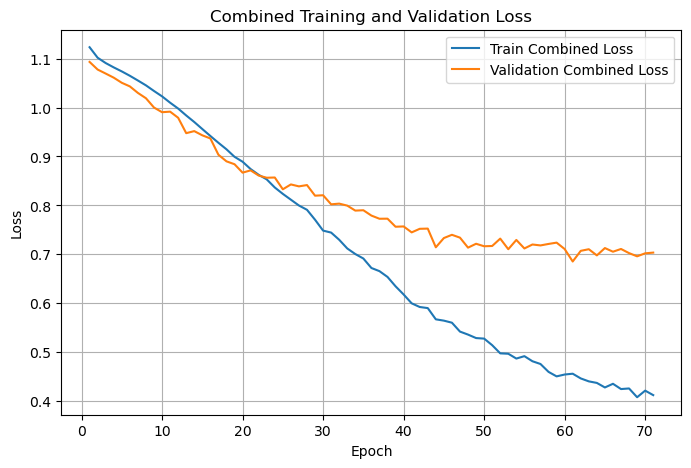

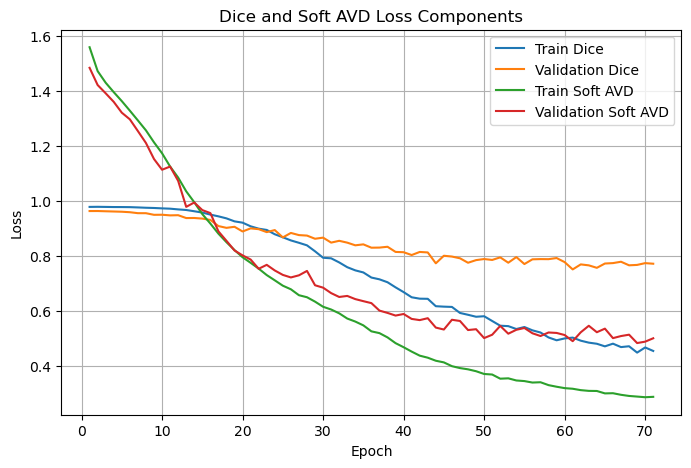

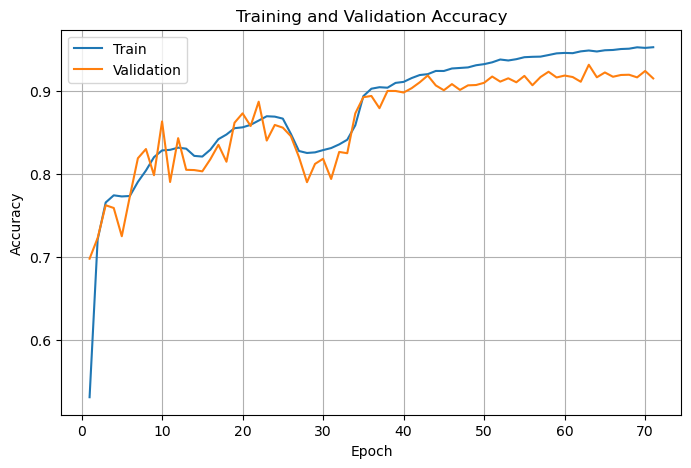

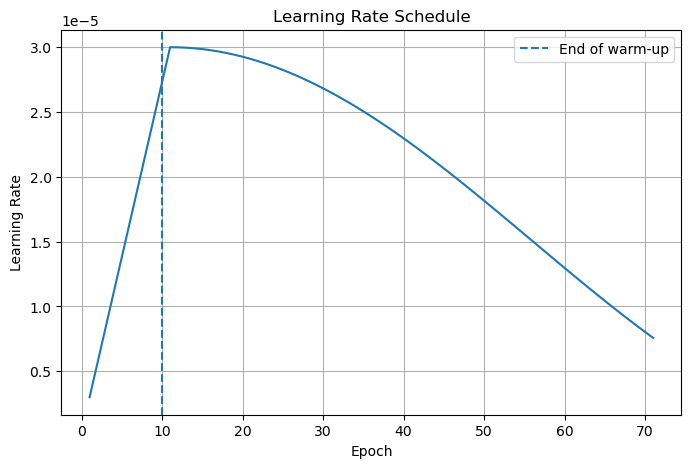

In [10]:
# ============================================================
# 9. Plot training history
# ============================================================

epochs = np.arange(
    1,
    len(training_history["train_loss"]) + 1,
)


# Combined training loss vs validation Dice loss
plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    training_history["train_loss"],
    label="Train Combined Loss",
)
plt.plot(
    epochs,
    training_history["validation_loss"],
    label="Validation Combined Loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Combined Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# Individual training loss components
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    training_history["train_dice_loss"],
    label="Train Dice",
)

plt.plot(
    epochs,
    training_history["validation_dice_loss"],
    label="Validation Dice",
)

plt.plot(
    epochs,
    training_history["train_avd_loss"],
    label="Train Soft AVD",
)

plt.plot(
    epochs,
    training_history["validation_avd_loss"],
    label="Validation Soft AVD",
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Dice and Soft AVD Loss Components"
)

plt.legend()
plt.grid(True)
plt.show()


# Accuracy
plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    training_history["train_accuracy"],
    label="Train",
)
plt.plot(
    epochs,
    training_history["validation_accuracy"],
    label="Validation",
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Learning rate
plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    training_history["learning_rate"],
)
plt.axvline(
    warmup_epochs,
    linestyle="--",
    label="End of warm-up",
)
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Schedule")
plt.legend()
plt.grid(True)
plt.show()


In [11]:
# ============================================================
# 10. Load best checkpoint and evaluate test set
# ============================================================

best_checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device,
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

print(
    "Loaded best checkpoint from epoch:",
    best_checkpoint["epoch"],
)

print(
    "Best validation combined loss:",
    best_checkpoint[
        "validation_loss"
    ],
)

print(
    "Validation Dice loss:",
    best_checkpoint[
        "validation_dice_loss"
    ],
)

print(
    "Validation Soft AVD loss:",
    best_checkpoint[
        "validation_avd_loss"
    ],
)

print(
    "Training loss weights:",
    f"Dice={best_checkpoint['dice_weight']}, "
    f"SoftAVD={best_checkpoint['avd_weight']}",
)


(
    test_loss,
    test_dice_loss,
    test_avd_loss,
    test_accuracy,
) = evaluate(
    model=model,
    loader=test_loader,
    dice_criterion=dice_criterion,
    avd_criterion=avd_criterion,
    device=device,
    dice_weight=DICE_WEIGHT,
    avd_weight=AVD_WEIGHT,
)

print()
print("Final test results")
print("------------------")

print(
    f"Test combined loss: "
    f"{test_loss:.6f}"
)

print(
    f"Test Dice loss:     "
    f"{test_dice_loss:.6f}"
)

print(
    f"Test Soft AVD loss: "
    f"{test_avd_loss:.6f}"
)

print(
    f"Test accuracy:      "
    f"{test_accuracy:.4f}"
)


/tmp/ipykernel_68501/3202656040.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best_checkpoint = torch.load(


Loaded best checkpoint from epoch: 61
Best validation combined loss: 0.6852748990058899
Validation Dice loss: 0.7505787852444227
Validation Soft AVD loss: 0.48936326217047776
Training loss weights: Dice=0.75, SoftAVD=0.25

Final test results
------------------
Test combined loss: 0.699676
Test Dice loss:     0.771083
Test Soft AVD loss: 0.485456
Test accuracy:      0.9276
